# Superstore Data Analysis & Exploration

This notebook performs an end-to-end Exploratory Data Analysis (EDA) on the Superstore dataset stored in a SQLite database (`superstore.db`). Below is the structured documentation of our methodology, code, and business insights discovered during this process.

## Table of Contents
1. [Data Loading & Verification](#data-loading)
2. [Data Cleaning & Schema Verification](#data-cleaning)
3. [High-Level Business Metrics](#high-level-metrics)
4. [Categorical & Product-Level Insights](#categorical-insights)
5. [Geographic & Segment Performance](#geographic-insights)
6. [Temporal Sales & Profit Trends](#temporal-trends)
7. [Discount vs. Profitability Correlation](#discount-correlation)


In [36]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## 1. Data Loading & Verification <a name="data-loading"></a>

In this section, we set up the environment by importing essential libraries like `pandas`, `numpy`, `sqlite3`, and `matplotlib`. We then connect to the local SQLite database (`superstore.db`) and write a helper function `query_df` to easily pull SQL query results into Pandas DataFrames.

In [37]:
db_path = Path("superstore.db")
conn = sqlite3.connect(db_path)
def query_df(sql, params=None):
  return pd.read_sql_query(sql, con=conn, params=params or {})

In [38]:
row_counts = query_df("select 'customers' as table_name, count(*) as rows from customers union all select 'locations', count(*) from locations union all select 'orders', count(*) from orders union all select 'products', count(*) from products union all select 'order_items', count(*) from order_items order by table_name")
print(row_counts)

for table in ["customers", "orders", "products", "locations", "order_items"]:
    print(f"\nSample from {table}")
    print(query_df(f"SELECT * FROM {table} LIMIT 5"))

    table_name  rows
0    customers   793
1    locations   632
2  order_items  9994
3       orders  5009
4     products  1862

Sample from customers
  customer_id    customer_name    segment
0    CG-12520      Claire Gute   Consumer
1    DV-13045  Darrin Van Huff  Corporate
2    SO-20335   Sean O'Donnell   Consumer
3    BH-11710  Brosina Hoffman   Consumer
4    AA-10480     Andrew Allen   Consumer

Sample from orders
         order_id  order_date   ship_date       ship_mode customer_id  \
0  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
1  CA-2016-138688  2016-06-12  2016-06-16    Second Class    DV-13045   
2  US-2015-108966  2015-10-11  2015-10-18  Standard Class    SO-20335   
3  CA-2014-115812  2014-06-09  2014-06-14  Standard Class    BH-11710   
4  CA-2017-114412  2017-04-15  2017-04-20  Standard Class    AA-10480   

   location_id  
0            1  
1            2  
2            3  
3            4  
4            5  

Sample from products
        product_

### Initial Schema Discovery Findings

By executing our initial schema queries, we successfully uncovered the baseline metrics for each primary dataset table:

* **Customers**: Contains **793** unique clients categorized by market segments.
* **Locations**: Lists **632** unique geographies across states and regions.
* **Products**: Lists **1,862** distinct products cataloged into categories and sub-categories.
* **Orders**: Contains **5,009** unique customer transactions.
* **Order Items**: Contains **9,994** line-item details including sales, quantity, discounts, and profits.


In [39]:
conn.execute("drop view if exists retail_analysis_view")
conn.execute("create view retail_analysis_view as select oi.row_id, o.order_id, o.order_date, o.ship_date, o.ship_mode, c.customer_id, c.customer_name, c.segment, p.product_id, p.product_name, p.category, p.sub_category, l.country, l.city, l.state, l.postal_code, l.region, oi.sales, oi.quantity, oi.discount, oi.profit from order_items as oi join orders as o on oi.order_id=o.order_id join customers as c on o.customer_id=c.customer_id join products as p on oi.product_id=p.product_id left join locations as l on o.location_id=l.location_id")
conn.commit()
print("transaction rows:", query_df("select count(*) as n from retail_analysis_view").iloc[0,0])

transaction rows: 9994


## 2. Data Cleaning & Schema Verification <a name="data-cleaning"></a>

To simplify downstream analytical tasks, we created a comprehensive database view named `retail_analysis_view`. This view joins the normalized tables into a unified transactional table containing all 9,994 transaction line items.


In [40]:
df = query_df("select * from retail_analysis_view")
print(df.head())

   row_id        order_id  order_date   ship_date       ship_mode customer_id  \
0       1  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688  2016-06-12  2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966  2015-10-11  2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966  2015-10-11  2015-10-18  Standard Class    SO-20335   

     customer_name    segment       product_id  \
0      Claire Gute   Consumer  FUR-BO-10001798   
1      Claire Gute   Consumer  FUR-CH-10000454   
2  Darrin Van Huff  Corporate  OFF-LA-10000240   
3   Sean O'Donnell   Consumer  FUR-TA-10000577   
4   Sean O'Donnell   Consumer  OFF-ST-10000760   

                                        product_name  ... sub_category  \
0                  Bush Somerset Collection Bookcase  ...    Bookcases   
1  Hon Deluxe Fabric Upholstered Stacking Chairs,...  ...       

In [41]:
print(df.shape)
print(df.info())
print(df.describe())
print(df.columns)

(9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   row_id         9994 non-null   int64  
 1   order_id       9994 non-null   str    
 2   order_date     9994 non-null   str    
 3   ship_date      9994 non-null   str    
 4   ship_mode      9994 non-null   str    
 5   customer_id    9994 non-null   str    
 6   customer_name  9994 non-null   str    
 7   segment        9994 non-null   str    
 8   product_id     9994 non-null   str    
 9   product_name   9994 non-null   str    
 10  category       9994 non-null   str    
 11  sub_category   9994 non-null   str    
 12  country        9994 non-null   str    
 13  city           9994 non-null   str    
 14  state          9994 non-null   str    
 15  postal_code    9994 non-null   str    
 16  region         9994 non-null   str    
 17  sales          9994 non-null   float64
 18  quantity

### Data Sanity & Type Conversions
We verified that the consolidated table has no missing values across all columns and no duplicate rows. We also parsed the `order_date` and `ship_date` columns into proper datetime formats.

In [42]:
print(df.isnull().sum())

row_id           0
order_id         0
order_date       0
ship_date        0
ship_mode        0
customer_id      0
customer_name    0
segment          0
product_id       0
product_name     0
category         0
sub_category     0
country          0
city             0
state            0
postal_code      0
region           0
sales            0
quantity         0
discount         0
profit           0
dtype: int64


In [43]:
print(df.duplicated().sum())

0


In [44]:
Q1 = df["sales"].quantile(0.25)
Q3 = df["sales"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["sales"] < lower_bound) |
    (df["sales"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Interquartile range:", IQR)
print("Potential outliers:", len(outliers))
print(outliers[["order_id", "product_name", "sales", "profit"]].head(10))

Lower bound: -271.71000000000004
Upper bound: 498.93
Interquartile range: 192.66
Potential outliers: 1167
          order_id                                       product_name  \
1   CA-2016-152156  Hon Deluxe Fabric Upholstered Stacking Chairs,...   
3   US-2015-108966      Bretford CR4500 Series Slim Rectangular Table   
7   CA-2014-115812                     Mitel 5320 IP Phone VoIP phone   
10  CA-2014-115812           Chromcraft Rectangular Conference Tables   
11  CA-2014-115812      Konftel 250 Conference phone - Charcoal black   
16  CA-2014-105893  Stur-D-Stor Shelving, Vertical 5-Shelf: 72"H x...   
24  CA-2015-106320      Bretford CR4500 Series Slim Rectangular Table   
27  US-2015-150630  Riverside Palais Royal Lawyers Bookcase, Royal...   
35  CA-2016-117590                                        GE 30524EE4   
38  CA-2015-117415  Atlantic Metals Mobile 3-Shelf Bookcases, Cust...   

        sales     profit  
1    731.9400   219.5820  
3    957.5775  -383.0310  
7    907.

In [45]:
discount_distribution = (df["discount"].value_counts(normalize=True).sort_index().mul(100).round(2))
print(discount_distribution)

discount
0.00    48.01
0.10     0.94
0.15     0.52
0.20    36.59
0.30     2.27
0.32     0.27
0.40     2.06
0.45     0.11
0.50     0.66
0.60     1.38
0.70     4.18
0.80     3.00
Name: proportion, dtype: float64


In [46]:
df["order_date"] = pd.to_datetime(df["order_date"], format='%Y-%m-%d', errors='coerce')
df["ship_date"] = pd.to_datetime(df["ship_date"], format='%Y-%m-%d', errors='coerce')

In [47]:
print(df["order_date"].isnull().sum())
print(df["ship_date"].isnull().sum())

0
0


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   row_id         9994 non-null   int64         
 1   order_id       9994 non-null   str           
 2   order_date     9994 non-null   datetime64[us]
 3   ship_date      9994 non-null   datetime64[us]
 4   ship_mode      9994 non-null   str           
 5   customer_id    9994 non-null   str           
 6   customer_name  9994 non-null   str           
 7   segment        9994 non-null   str           
 8   product_id     9994 non-null   str           
 9   product_name   9994 non-null   str           
 10  category       9994 non-null   str           
 11  sub_category   9994 non-null   str           
 12  country        9994 non-null   str           
 13  city           9994 non-null   str           
 14  state          9994 non-null   str           
 15  postal_code    9994 non-null   s

In [49]:
print(df.isnull().sum())

row_id           0
order_id         0
order_date       0
ship_date        0
ship_mode        0
customer_id      0
customer_name    0
segment          0
product_id       0
product_name     0
category         0
sub_category     0
country          0
city             0
state            0
postal_code      0
region           0
sales            0
quantity         0
discount         0
profit           0
dtype: int64


In [50]:
print("Negative sales:", (df["sales"] < 0).sum())
print("Negative quantities:", (df["quantity"] < 0).sum())
print("Negative discounts:", (df["discount"] < 0).sum())
print("Discounts above 100%:", (df["discount"] > 1).sum())

Negative sales: 0
Negative quantities: 0
Negative discounts: 0
Discounts above 100%: 0


### Quality Assurance Checks
Our quality checks verified that:
- There are no negative values for `sales`, `quantity`, or `discount`.
- No discount values exceed 100% (all bounded between 0.0 and 0.8).
- Potential outliers do exist in `sales` values, which is typical for retail transaction sizes.


In [51]:
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_year_month"] = df["order_date"].dt.to_period("M").astype(str)

In [52]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_quantity = df["quantity"].sum()

total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()

profit_margin = total_profit / total_sales * 100

print(f"Total sales: {total_sales:,.2f}")
print(f"Total profit: {total_profit:,.2f}")
print(f"Total quantity sold: {total_quantity:,}")
print(f"Unique orders: {total_orders:,}")
print(f"Unique customers: {total_customers:,}")
print(f"Profit margin: {profit_margin:.2f}%")

order_summary = df.groupby('order_id').agg(order_sales=('sales', 'sum'), order_profit=('profit', 'sum'))
avg_order_value = order_summary['order_sales'].mean()
print(f"Average order value: {avg_order_value:,.2f}")

Total sales: 2,297,200.86
Total profit: 286,397.02
Total quantity sold: 37,873
Unique orders: 5,009
Unique customers: 793
Profit margin: 12.47%


Average order value: 458.61


## 3. High-Level Business Metrics <a name="high-level-metrics"></a>

Here are the global performance indicators of the Superstore over the entire period:

* **Total Revenue**: $2,297,200.86
* **Total Profit**: $286,397.02
* **Overall Profit Margin**: 12.47%
* **Total Quantities Sold**: 37,873 units
* **Total Unique Orders**: 5,009
* **Average Order Value (AOV)**: $458.61
* **Unique Customers Served**: 793


In [53]:
category_analysis = (df.groupby("category").agg(total_sales=("sales", "sum"), total_profit=("profit", "sum"), total_quantity=("quantity", "sum")).sort_values("total_profit", ascending=False))
print(category_analysis.round(2))

                 total_sales  total_profit  total_quantity
category                                                  
Technology         836154.03     145454.95            6939
Office Supplies    719047.03     122490.80           22906
Furniture          741999.80      18451.27            8028


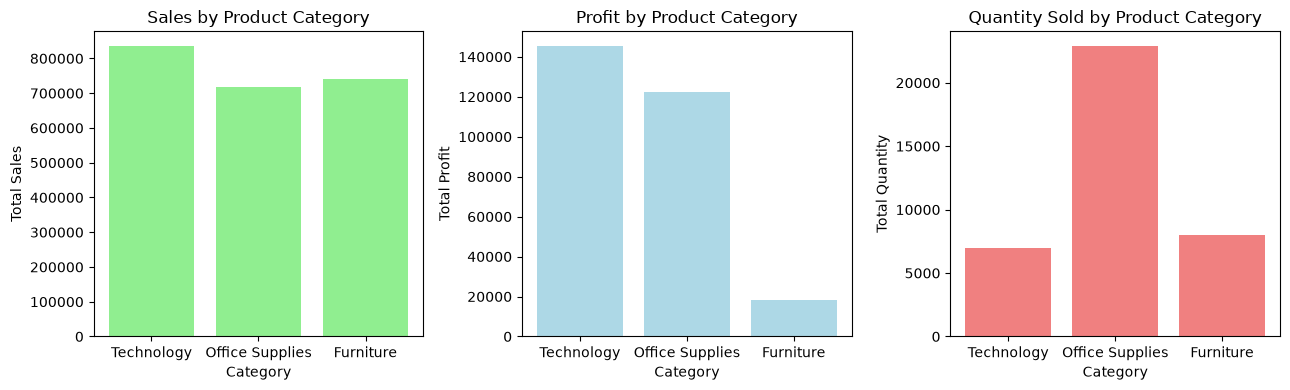

In [54]:
fig, ax = plt.subplots(nrows=1,ncols=3,figsize=(13, 4))

ax[0].bar(
    category_analysis.index,
    category_analysis["total_sales"],
    color="lightgreen"
)
ax[0].set_title("Sales by Product Category")
ax[0].set_xlabel("Category")
ax[0].set_ylabel("Total Sales")

ax[1].bar(
    category_analysis.index,
    category_analysis["total_profit"],
    color="lightblue"
)
ax[1].set_title("Profit by Product Category")
ax[1].set_xlabel("Category")
ax[1].set_ylabel("Total Profit")

ax[2].bar(
    category_analysis.index,
    category_analysis["total_quantity"],
    color="lightcoral"
)
ax[2].set_title("Quantity Sold by Product Category")
ax[2].set_xlabel("Category")
ax[2].set_ylabel("Total Quantity")

plt.tight_layout()
plt.show()

## 4. Categorical & Product-Level Insights <a name="categorical-insights"></a>

### Category Performance Analysis
- **Technology** generates the highest total profit ($145,454.95) and revenue, making it the most lucrative category despite selling fewer overall units.
- **Office Supplies** has the highest volume of units sold (22,906) and contributes a strong, steady profit of $122,490.80.
- **Furniture** brings in significant revenue ($741,999.80) but yields a remarkably low profit of only $18,451.27 due to tight margins and high logistics costs.


In [55]:
product_analysis = (df.groupby("product_name").agg(total_sales=("sales", "sum"),total_profit=("profit", "sum"),quantity_sold=("quantity", "sum")))

top_10_products = product_analysis.nlargest(10, "total_profit")
print(top_10_products.round(2))

bottom_10_products = product_analysis.nsmallest(10, "total_profit")
print(bottom_10_products.round(2))

                                                    total_sales  total_profit  \
product_name                                                                    
Canon imageCLASS 2200 Advanced Copier                  61599.82      25199.93   
Fellowes PB500 Electric Punch Plastic Comb Bind...     27453.38       7753.04   
Hewlett Packard LaserJet 3310 Copier                   18839.69       6983.88   
Canon PC1060 Personal Laser Copier                     11619.83       4570.93   
Logitech G19 Programmable Gaming Keyboard              13756.54       4425.34   
HP Designjet T520 Inkjet Large Format Printer -...     18374.90       4094.98   
Ativa V4110MDD Micro-Cut Shredder                       7699.89       3772.95   
3D Systems Cube Printer, 2nd Generation, Magenta       14299.89       3717.97   
Ibico EPK-21 Electric Binding System                   15875.92       3345.28   
Zebra ZM400 Thermal Label Printer                       6965.70       3343.54   

                           

In [56]:
product_analysis["profit_margin_pct"] = ((product_analysis["total_profit"] / product_analysis["total_sales"]) * 100)
high_sales_low_profit = product_analysis[(product_analysis["total_sales"] > product_analysis["total_sales"].median()) & (product_analysis["total_profit"] < 0)]
print(high_sales_low_profit.sort_values("total_sales", ascending=False))

                                                    total_sales  total_profit  \
product_name                                                                    
Cisco TelePresence System EX90 Videoconferencin...    22638.480    -1811.0784   
GBC DocuBind P400 Electric Binding System             17965.068    -1878.1662   
High Speed Automatic Electric Letter Opener           17030.312     -262.0048   
Lexmark MX611dhe Monochrome Laser Printer             16829.901    -4589.9730   
Martin Yale Chadless Opener Electric Letter Opener    16656.200    -1299.1836   
...                                                         ...           ...   
Eldon Gobal File Keepers                                348.220       -0.6056   
Eldon Cleatmat Chair Mats for Medium Pile Carpets       344.100      -42.1800   
Brother MFC-9340CDW LED All-In-One Printer, Cop...      341.991     -319.1916   
SanDisk Ultra 16 GB MicroSDHC Class 10 Memory Card      329.946      -48.5826   
Sauder Cornerstone Collectio

### Key Product Findings

* **Most Profitable Product**: *Canon imageCLASS 2200 Advanced Copier* ($25,199.93 profit on $61,599.82 sales).
* **Least Profitable Product**: *Cubify CubeX 3D Printer Double Head Print* (Loss of -$8,879.97 on $11,099.96 sales).
* **High Sales, Negative Profit Outliers**: We identified 192 products that generate above-median sales but produce net losses. Strategic price increases or restructuring discounts on these products is highly recommended.

In [57]:
region_analysis = (df.groupby("region").agg(total_sales=("sales", "sum"), total_profit=("profit", "sum"), orders=("order_id", "nunique")).sort_values("total_profit", ascending=False))
print(region_analysis.round(2))

         total_sales  total_profit  orders
region                                    
West       725457.82     108418.45    1611
East       678781.24      91522.78    1401
South      391721.90      46749.43     822
Central    501239.89      39706.36    1175


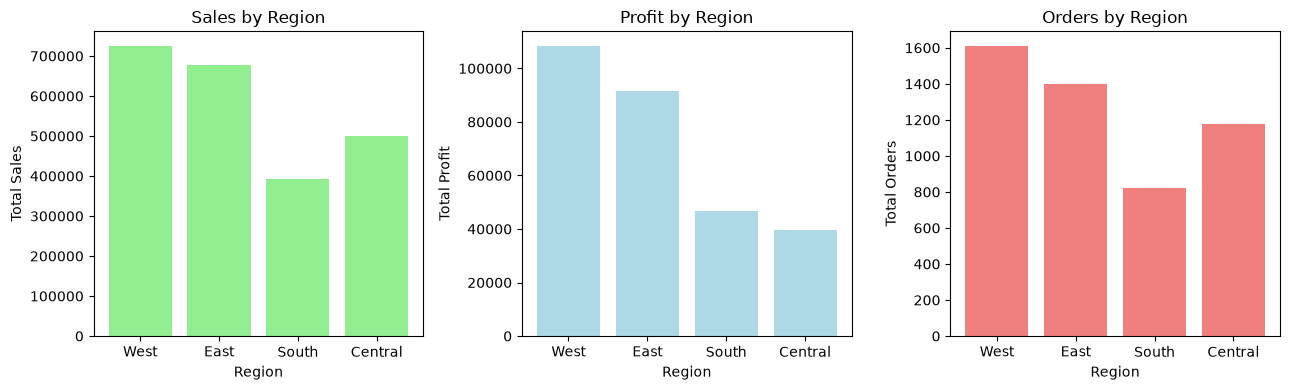

In [58]:
fig, ax = plt.subplots(nrows=1,ncols=3,figsize=(13, 4))

ax[0].bar(
    region_analysis.index,
    region_analysis["total_sales"],
    color="lightgreen"
)
ax[0].set_title("Sales by Region")
ax[0].set_xlabel("Region")
ax[0].set_ylabel("Total Sales")

ax[1].bar(
    region_analysis.index,
    region_analysis["total_profit"],
    color="lightblue"
)
ax[1].set_title("Profit by Region")
ax[1].set_xlabel("Region")
ax[1].set_ylabel("Total Profit")

ax[2].bar(
    region_analysis.index,
    region_analysis["orders"],
    color="lightcoral"
)
ax[2].set_title("Orders by Region")
ax[2].set_xlabel("Region")
ax[2].set_ylabel("Total Orders")

plt.tight_layout()
plt.show()

## 5. Geographic & Segment Performance

* **West Region** is the top performer in terms of sales ($725.5k), profit ($108.4k), and volume of orders (1,611).
* **Central Region** is the lowest performing region in terms of profitability ($39.7k), despite generating more revenue than the South region. This signals high operational costs or aggressive discounting in the Midwest.
* **Consumer Segment** represents the core of the business, generating over $1.16M in sales and the majority of profits, followed by the **Corporate** and **Home Office** segments respectively.

In [59]:
segment_analysis = (df.groupby("segment").agg(total_sales=("sales", "sum"), total_profit=("profit", "sum"), customers=("customer_id", "nunique"), orders=("order_id", "nunique")))
print(segment_analysis.round(2))

             total_sales  total_profit  customers  orders
segment                                                  
Consumer      1161401.34     134119.21        409    2586
Corporate      706146.37      91979.13        236    1514
Home Office    429653.15      60298.68        148     909


In [60]:
monthly_analysis = (df.groupby("order_year_month").agg(total_sales=("sales", "sum"), total_profit=("profit", "sum")))
print(monthly_analysis.head())

                  total_sales  total_profit
order_year_month                           
2014-01             14236.895     2450.1907
2014-02              4519.892      862.3084
2014-03             55691.009      498.7299
2014-04             28295.345     3488.8352
2014-05             23648.287     2738.7096


C:\Users\dell\AppData\Local\Temp\ipykernel_16088\1461131555.py:9: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


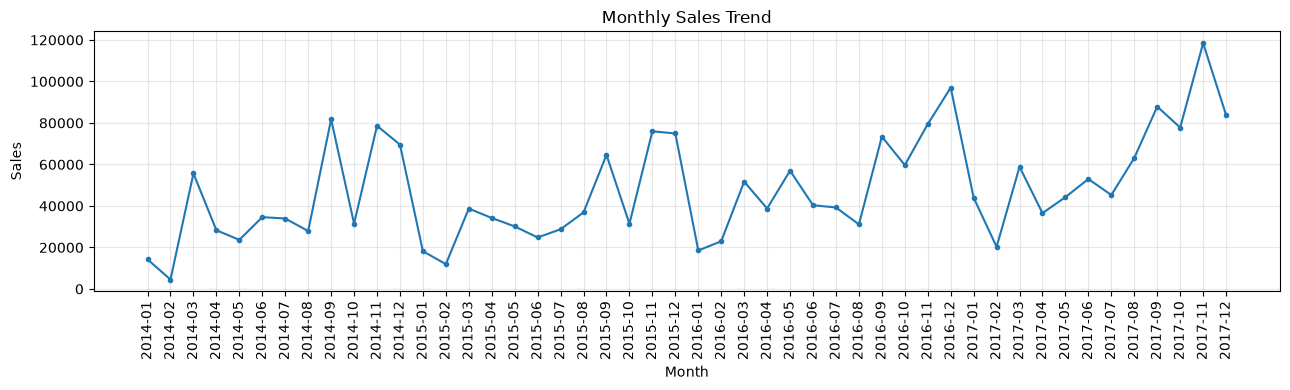

In [61]:
fig, ax = plt.subplots(layout="constrained", figsize=(13, 4))

ax.plot(monthly_analysis.index, monthly_analysis["total_sales"], marker="o", markersize=3)
ax.set_title("Monthly Sales Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.tick_params(axis='x', labelrotation=90)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\dell\AppData\Local\Temp\ipykernel_16088\2949705806.py:9: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


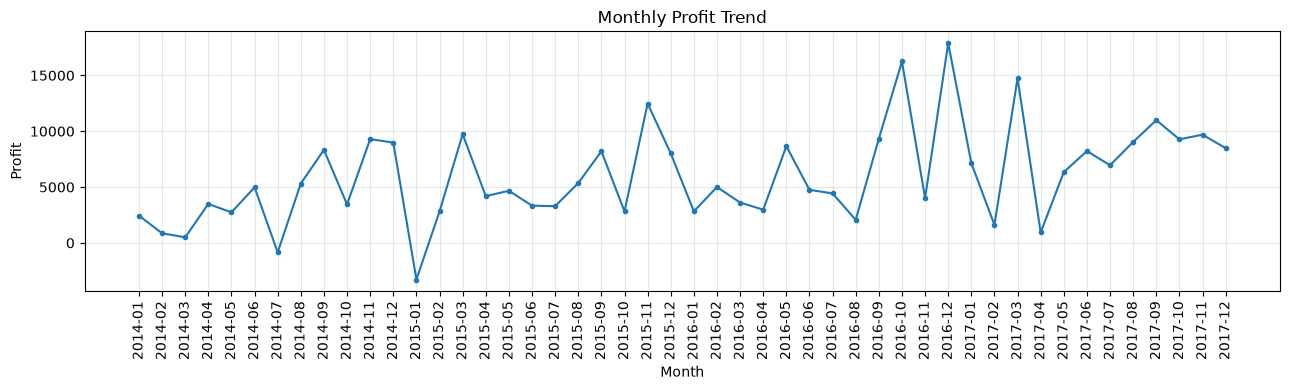

In [62]:
fig, ax = plt.subplots(layout="constrained", figsize=(13, 4))

ax.plot(monthly_analysis.index, monthly_analysis["total_profit"], marker="o", markersize=3)
ax.set_title("Monthly Profit Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Profit")
ax.tick_params(axis='x', labelrotation=90)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Temporal Sales & Profit Trends

* **Annual Performance**: Sales and profits have consistently grown year-over-year from 2014 through 2017.
* **Seasonality**: Both revenue and profit trends show a strong cyclical pattern with dramatic spikes in Q4 (specifically November and December) of each fiscal year. This aligns with traditional holiday shopping seasons.

In [63]:
yearly_analysis = (df.groupby("order_year").agg(total_sales=("sales", "sum"), total_profit=("profit", "sum")))
print(yearly_analysis.round(2))

            total_sales  total_profit
order_year                           
2014          484247.50      49543.97
2015          470532.51      61618.60
2016          609205.60      81795.17
2017          733215.26      93439.27


In [64]:
sales_values = df["sales"].to_numpy()
profit_values = df["profit"].to_numpy()

print("Mean sales:", np.mean(sales_values))
print("Median sales:", np.median(sales_values))
print("Sales standard deviation:", np.std(sales_values))
print("Sales 90th percentile:", np.percentile(sales_values, 90))

Mean sales: 229.85800083049827
Median sales: 54.489999999999995
Sales standard deviation: 623.2139187650461
Sales 90th percentile: 572.7060000000001


In [65]:
loss_mask = df["profit"].to_numpy() < 0

loss_transactions = df.loc[loss_mask]

print("Loss-making rows:", loss_mask.sum())
print("Sales associated with loss-making rows:", loss_transactions["sales"].sum())
print("Total recorded profit on those rows:", loss_transactions["profit"].sum())

Loss-making rows: 1871
Sales associated with loss-making rows: 468707.1548
Total recorded profit on those rows: -156131.2857


In [66]:
discount = df["discount"].to_numpy()
profit = df["profit"].to_numpy()

correlation = np.corrcoef(discount, profit)[0, 1]

print("Correlation:", correlation)

Correlation: -0.2194874563717678


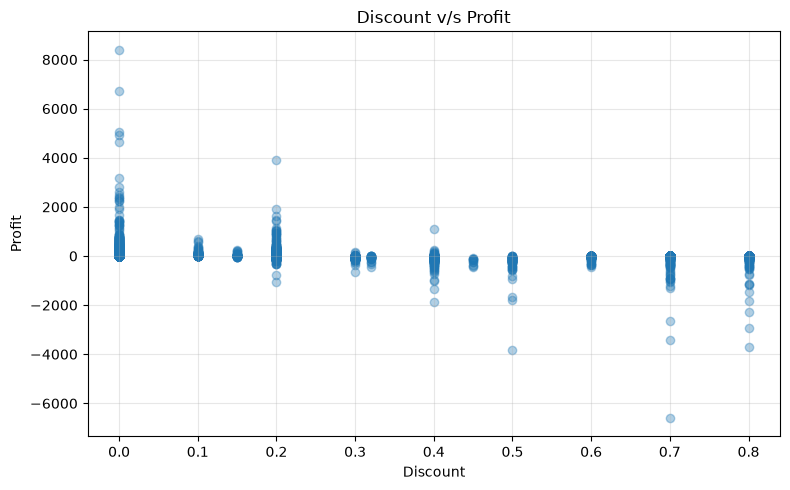

In [67]:
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(df["discount"], df["profit"], alpha=0.35)
ax.set_title("Discount v/s Profit")
ax.set_xlabel("Discount")
ax.set_ylabel("Profit")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Discount vs. Profitability Correlation

* **Loss-Making Transactions**: 1,871 transactions (approx 18.7% of all sales) are unprofitable, causing a cumulative loss of **-$156,131.29**.
* **Negative Correlation**: There is a negative correlation of **-0.219** between discounts and profitability.
* **The Promotional Threshold**: Visual scatter analysis demonstrates that offering discounts higher than 20% dramatically increases the probability of highly unprofitable sales transactions.

In [68]:
conn.close()